# 01 — Dataset Exploration

# Project

Computer Vision-Based Athlete Performance Analysis and Injury Risk Assessment Using Pose Estimation and Motion Tracking
# Objective

The objective of this notebook is to explore the workout-video dataset, understand the distribution of exercise categories, inspect sample videos, and evaluate basic video quality before applying pose estimation.

# Research Questions

1. How many videos and exercise categories are available?

2. How balanced is the dataset across exercise categories?

3. Are the videos readable, and what are their basic properties?

4. Are the videos suitable for extracting human pose landmarks?

In [1]:
from pathlib import Path
import pandas as pd 
from IPython.display import Video, display
import matplotlib.pyplot as plt
import cv2
import numpy as np

In [2]:
import sys
print(sys.executable)

c:\athlete-performance-injury-risk\.venv\Scripts\python.exe


In [3]:

print("Current folder:", Path.cwd())

project = Path.cwd()

print("\nFolders and files here:")
for item in project.iterdir():
    print(item.name)

print("\nSearching for archive(5)...")
for path in project.rglob("archive(5)"):
    if path.is_dir():
        print("Found:", path)
        

Current folder: c:\athlete-performance-injury-risk\notebooks

Folders and files here:
01_dataset_exploration.ipynb

Searching for archive(5)...


In [4]:

dataset_folder = Path("..") / "data" / "archive(5)"

print("Dataset path:", dataset_folder.resolve())
print("Folder exists:", dataset_folder.exists())

Dataset path: C:\athlete-performance-injury-risk\data\archive(5)
Folder exists: True


In [5]:
# all supported vidoes files 
video_ext = {".mp4", ".mov", ".avi", ".mkv"}
video_files = []
for file_path in dataset_folder.rglob("*"):
    # Check whether this is a file, not a folder
    if file_path.is_file():
        # file extension
        extension = file_path.suffix.lower()
        if extension in video_ext:
            video_files.append(file_path)
            
print("Total videos found:", len(video_files))
print("\nFirst 5 video paths:") 
for video_path in video_files[:5]:
    print(video_path)
    

Total videos found: 652

First 5 video paths:
..\data\archive(5)\barbell biceps curl\barbell biceps curl_1.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_10.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_11.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_12.mp4
..\data\archive(5)\barbell biceps curl\barbell biceps curl_13.mp4


In [6]:
exercise_counts = {}

for video_path in video_files:
    #name of the folder containing this video
    exercise_name = video_path.parent.name
    # If this exercise is already in the dictionary, add 1
    if exercise_name in exercise_counts:
        exercise_counts[exercise_name] += 1
    # Otherwise,a new entry with count 1
    else:
        exercise_counts[exercise_name] = 1

# Sort exercises from the most videos to the fewest
sorted_exercises = sorted(exercise_counts.items(),key=lambda item: item[1],reverse=True)
print("Total exercise categories:", len(exercise_counts))
print("\nVideos per exercise:\n")

for exercise_name, count in sorted_exercises:
    print(exercise_name, ":", count)

Total exercise categories: 22

Videos per exercise:

barbell biceps curl : 62
bench press : 61
push-up : 56
lat pulldown : 51
tricep Pushdown : 50
lateral raise : 37
incline bench press : 33
deadlift : 32
squat : 29
chest fly machine : 28
pull Up : 26
leg extension : 25
leg raises : 21
t bar row : 21
tricep dips : 20
hammer curl : 19
hip thrust : 18
shoulder press : 17
romanian deadlift : 14
russian twist : 13
decline bench press : 12
plank : 7


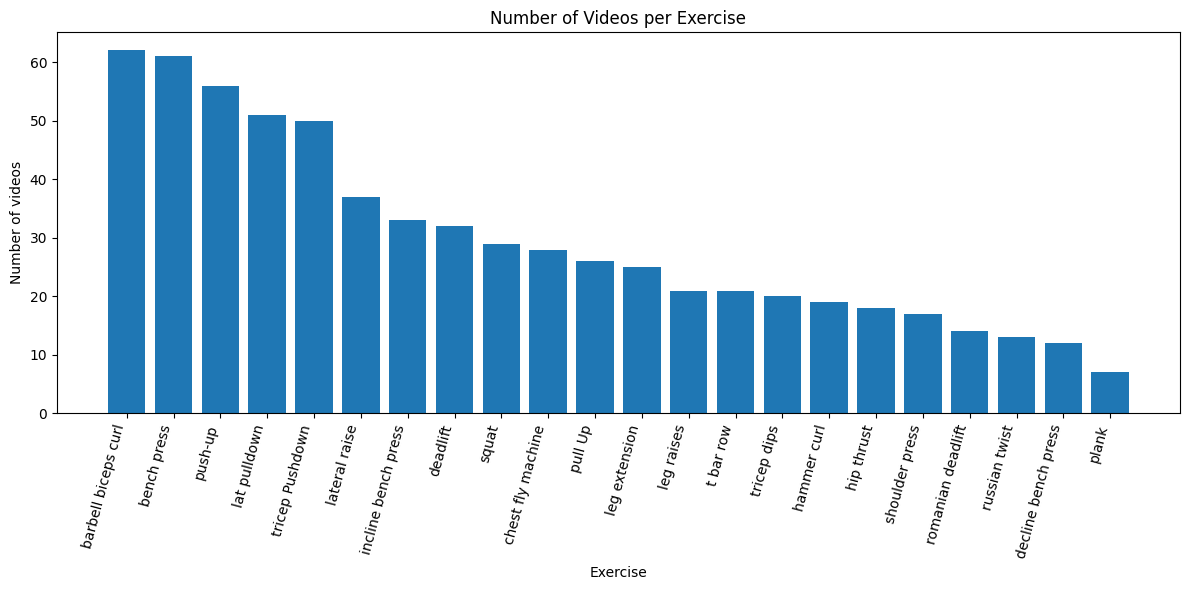

In [7]:
# bar chart
exercise_names = [item[0] for item in sorted_exercises]
counts = [item[1] for item in sorted_exercises]

plt.figure(figsize=(12, 6))
plt.bar(exercise_names, counts)
plt.xticks(rotation=75, ha="right")
plt.xlabel("Exercise")
plt.ylabel("Number of videos")
plt.title("Number of Videos per Exercise")
plt.tight_layout()
plt.show()

In [8]:
# inspect video sample 
sample_video = video_files[0]
print("Sample video:", sample_video)
display(Video(str(sample_video), embed=False))

Sample video: ..\data\archive(5)\barbell biceps curl\barbell biceps curl_1.mp4


In [9]:
# dataset summary 
print("Total videos:", len(video_files))
print("Total exercise categories:", len(exercise_counts))
print("Minimum videos in one category:", min(exercise_counts.values()))
print("Maximum videos in one category:", max(exercise_counts.values()))

Total videos: 652
Total exercise categories: 22
Minimum videos in one category: 7
Maximum videos in one category: 62


In [10]:
print("Top 5 exercises:")
for name, count in sorted_exercises[:5]:
    print(f"{name}: {count} videos")

print("\nBottom 5 exercises:")
for name, count in sorted_exercises[-5:]:
    print(f"{name}: {count} videos")
    

Top 5 exercises:
barbell biceps curl: 62 videos
bench press: 61 videos
push-up: 56 videos
lat pulldown: 51 videos
tricep Pushdown: 50 videos

Bottom 5 exercises:
shoulder press: 17 videos
romanian deadlift: 14 videos
russian twist: 13 videos
decline bench press: 12 videos
plank: 7 videos


Video: ..\data\archive(5)\barbell biceps curl\barbell biceps curl_1.mp4
Frame read successfully: True


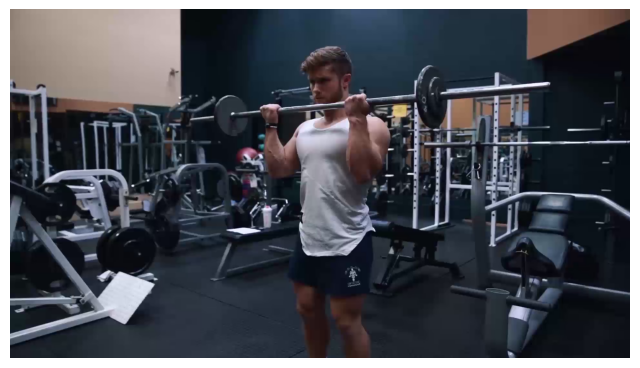

In [11]:

sample_video = str(video_files[0])

cap = cv2.VideoCapture(sample_video)
success, frame = cap.read()
cap.release()

print("Video:", sample_video)
print("Frame read successfully:", success)

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 5))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.show()

In [12]:
# inspect video metadata 
video_metadata = []

for video_path in video_files:
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        video_metadata.append({
            "video": video_path.name,
            "exercise": video_path.parent.name,
            "readable": False,
            "fps": None,
            "frame_count": None,
            "duration_seconds": None,
            "width": None,
            "height": None
        })
        cap.release()
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = frame_count / fps if fps > 0 else None

    video_metadata.append({
        "video": video_path.name,
        "exercise": video_path.parent.name,
        "readable": True,
        "fps": fps,
        "frame_count": frame_count,
        "duration_seconds": duration,
        "width": width,
        "height": height
    })

    cap.release()

metadata_df = pd.DataFrame(video_metadata)

print("Total videos checked:", len(metadata_df))

Total videos checked: 652


In [13]:
print("Total videos:", len(metadata_df))
print("Readable videos:", metadata_df["readable"].sum())
print("Unreadable videos:", (~metadata_df["readable"]).sum())

metadata_df.head()

Total videos: 652
Readable videos: 652
Unreadable videos: 0


,video,exercise,readable,fps,frame_count,duration_seconds,width,height
0,barbell biceps curl_1.mp4,barbell biceps curl,True,29.97003,114,3.803800,1920,1080
1,barbell biceps curl_10.mp4,barbell biceps curl,True,29.97003,94,3.136467,1920,1080
2,barbell biceps curl_11.mp4,barbell biceps curl,True,29.97003,75,2.502500,1920,1080
3,barbell biceps curl_12.mp4,barbell biceps curl,True,29.97003,123,4.104100,1920,1080
4,barbell biceps curl_13.mp4,barbell biceps curl,True,29.97003,122,4.070733,1920,1080


In [14]:
metadata_df.describe()

,fps,frame_count,duration_seconds,width,height
count,652.000000,652.000000,652.000000,652.000000,652.000000
mean,28.570123,223.782209,7.858230,1578.122699,894.144172
std,3.057950,334.696536,11.632698,338.189428,202.133803
min,23.976024,30.000000,1.001000,320.000000,240.000000
25%,25.000000,82.000000,2.919583,1280.000000,720.000000
50%,29.970030,147.500000,5.005000,1280.000000,720.000000
75%,29.970030,272.750000,9.859850,1920.000000,1080.000000
max,60.000000,6840.000000,228.000000,1920.000000,1920.000000


In [15]:
print(metadata_df.isnull().sum())

video               0
exercise            0
readable            0
fps                 0
frame_count         0
duration_seconds    0
width               0
height              0
dtype: int64


In [16]:
# summarize video properties
print("Video duration (seconds):")
print(metadata_df["duration_seconds"].describe().round(2))

print("\nFrame rate (FPS):")
print(metadata_df["fps"].describe().round(2))

print("\nVideo resolution (width x height):")
print(
    metadata_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

Video duration (seconds):
count    652.00
mean       7.86
std       11.63
min        1.00
25%        2.92
50%        5.00
75%        9.86
max      228.00
Name: duration_seconds, dtype: float64

Frame rate (FPS):
count    652.00
mean      28.57
std        3.06
min       23.98
25%       25.00
50%       29.97
75%       29.97
max       60.00
Name: fps, dtype: float64

Video resolution (width x height):
width  height
1280   720       321
1920   1080      306
       1440        8
640    360         6
1080   608         5
988    556         2
320    240         1
1080   1920        1
1280   676         1
       714         1
dtype: int64


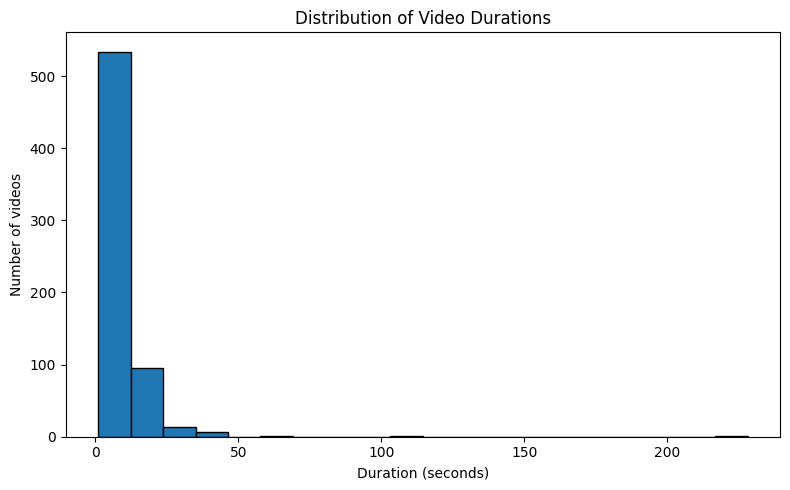

In [17]:
plt.figure(figsize=(8, 5))
plt.hist(metadata_df["duration_seconds"], bins=20, edgecolor="black")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of videos")
plt.title("Distribution of Video Durations")
plt.tight_layout()
plt.show()

In [18]:
output_folder = Path("../outputs")
output_folder.mkdir(parents=True, exist_ok=True)

metadata_df.to_csv(
    output_folder / "video_metadata.csv",
    index=False
)

print("Saved to:", (output_folder / "video_metadata.csv").resolve())

Saved to: C:\athlete-performance-injury-risk\outputs\video_metadata.csv


In [19]:
resolution_counts = (
    metadata_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

print("Top 10 video resolutions:")
print(resolution_counts.head(10))

Top 10 video resolutions:
width  height
1280   720       321
1920   1080      306
       1440        8
640    360         6
1080   608         5
988    556         2
320    240         1
1080   1920        1
1280   676         1
       714         1
dtype: int64


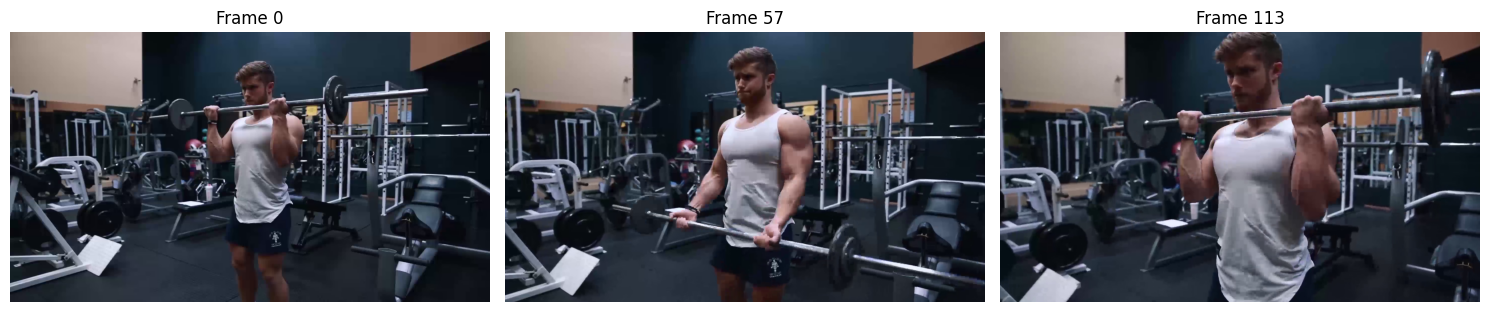

In [20]:
sample_video = str(video_files[0])

cap = cv2.VideoCapture(sample_video)
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

if cap.isOpened() and frame_count > 0:
    sample_indices = [
        0,
        frame_count // 2,
        frame_count - 1
    ]

    frames = []

    for frame_index in sample_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
        success, frame = cap.read()

        if success:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append((frame_index, frame))

    cap.release()

    fig, axes = plt.subplots(
        1, len(frames), figsize=(15, 5)
    )

    if len(frames) == 1:
        axes = [axes]

    for ax, (frame_index, frame) in zip(axes, frames):
        ax.imshow(frame)
        ax.set_title(f"Frame {frame_index}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    cap.release()
    print("Could not read the sample video.")

In [21]:

# Check whether video metadata contains invalid values

checks = {
    "Invalid FPS": metadata_df["fps"].isna().sum()
    + (metadata_df["fps"] <= 0).sum(),

    "Invalid frame count": metadata_df["frame_count"].isna().sum()
    + (metadata_df["frame_count"] <= 0).sum(),

    "Invalid width": metadata_df["width"].isna().sum()
    + (metadata_df["width"] <= 0).sum(),

    "Invalid height": metadata_df["height"].isna().sum()
    + (metadata_df["height"] <= 0).sum(),

    "Invalid duration": metadata_df["duration_seconds"].isna().sum()
    + (metadata_df["duration_seconds"] <= 0).sum()
}

for check, count in checks.items():
    print(f"{check}: {count}")


Invalid FPS: 0
Invalid frame count: 0
Invalid width: 0
Invalid height: 0
Invalid duration: 0


In [22]:

# Select one sample video from five exercise categories

sample_categories = [name for name, count in sorted_exercises[:5]]

for category in sample_categories:
    category_videos = [path for path in video_files if path.parent.name == category]

    if category_videos:
        sample_path = category_videos[0]

        print(f"\nExercise: {category}")
        print(f"Video: {sample_path.name}")

        display(Video(str(sample_path), embed=False))



Exercise: barbell biceps curl
Video: barbell biceps curl_1.mp4



Exercise: bench press
Video: bench press_1.mp4



Exercise: push-up
Video: push-up_1.mp4



Exercise: lat pulldown
Video: lat pulldown_1.mp4



Exercise: tricep Pushdown
Video: tricep pushdown_1.mp4


## Dataset Exploration: Findings and Conclusion

The dataset contains **652 workout videos across 22 exercise categories**. All 652 videos were readable during the initial OpenCV check.

### 1. Video Duration and Frame Rate

The video durations vary across the dataset:

- Mean duration: 7.86 seconds
- Median duration: 5.00 seconds
- Minimum duration: 1.00 second
- Maximum duration: 228.00 seconds
- Median frame rate: approximately 29.97 FPS

The average duration is higher than the median, which suggests that some videos are much longer than most others. These differences should be considered when selecting frames for analysis.

### 2. Video Resolution

The most common video resolutions are:

- **1280 × 720 pixels (HD):** 321 videos
- **1920 × 1080 pixels (Full HD):** 306 videos

Together, these resolutions account for approximately 96.2% of the dataset. The remaining videos have different resolutions, including lower-resolution and portrait videos.

For consistent processing, frames may be resized when needed. However, the original aspect ratio should be preserved to avoid changing body proportions.

### 3. Metadata Validation

The metadata checks returned the following results:

- Invalid FPS: 0
- Invalid frame count: 0
- Invalid width: 0
- Invalid height: 0
- Invalid duration: 0

These results show that all videos passed the basic metadata checks performed in this notebook.

### 4. Sample Video Inspection

Five sample videos from different exercise categories were displayed for an initial visual inspection. This helps us understand how the exercises are recorded and whether the videos may be suitable for pose estimation.

Further inspection is needed to check body visibility, camera angles, lighting, motion blur, and whether important joints remain visible during movement.

### 5. Limitations

Although all videos were readable, this does not guarantee that every video contains a complete exercise repetition or that all body landmarks can be detected correctly.

The dataset contains exercise categories but does not provide verified injury outcomes. Therefore, it cannot be used alone to validate actual injury prediction.

### 6. Conclusion and Next Steps

The initial exploration provides a useful understanding of the dataset, its exercise categories, and its video properties. The videos appear suitable for further investigation, but their pose-estimation quality still needs to be tested.

The next step is to apply a pretrained human pose-estimation model to a small sample of videos. We will then check landmark visibility and detection quality before calculating joint angles, range of motion, and repetition timing.